# Движуха: анализ аудитории и эффективности привлечения
## PA-S1 · Осень 2026 · Командный трек А

**Команда:** Станислав, Андрей, Даниил и Елена.
**Репозиторий:** [Dvizhuha_PA](https://github.com/Andre1ka11/Dvizhuha_PA).

В этой работе мы рассматриваем сервис поиска мероприятий и покупки билетов.
Нам нужно понять, как посетители становятся покупателями, возвращаются ли они
и насколько их покупки покрывают расходы на привлечение. Для первого анализа
используем исторические данные Afisha: визиты, покупки и рекламные расходы.

Сначала описываем продукт и проверяем данные. Затем фиксируем определения,
выбираем метрики и план событий, после чего рассчитываем начальные показатели.
В конце разбираем этические вопросы и задаём критерии для следующих этапов проекта.
Такой порядок позволяет связать каждое решение с конкретными данными и расчётами.

## 1. Какой продукт мы исследуем

**Движуха** — концепция сервиса, в котором можно найти городское мероприятие
и купить билет. Основная аудитория — люди, которые хотят выбрать, куда сходить,
но тратят время на поиск и сравнение предложений на разных площадках.
Для организаторов сервис должен стать каналом продаж с понятной стоимостью привлечения покупателя.

Мы предполагаем, что объединение поиска и покупки в одном сервисе поможет пользователю
быстрее перейти от желания посетить мероприятие к покупке билета. Если опыт окажется полезным,
у человека появится причина вернуться при следующем выборе досуга. Это **гипотеза ценности**:
её предстоит проверять, поскольку в выбранных таблицах нет информации о мотивах пользователей
и удобстве интерфейса.

Предполагаемая **бизнес-модель** — комиссия или сервисный сбор с продажи билета.
Поэтому для нас важны одновременно число покупателей и затраты на их привлечение:
рост посещаемости сам по себе ещё не означает рост бизнеса.

Данные Afisha используем как исторический пример работы похожего сервиса.
Они позволяют проверить подход к измерению продукта, но не подтверждают спрос именно на «Движуху».
В рамках проекта хотим ответить на три вопроса:

1. Какая доля новых посетителей доходит до покупки?
2. Как часто пользователи возвращаются в следующие месяцы?
3. В каких каналах выручка привлечённых покупателей лучше покрывает рекламные расходы?

Ответы помогут выбрать направления дальнейшей проверки: путь к покупке, причины возврата
и эффективность каналов. Окончательные решения об изменении продукта или бюджета потребуют
дополнительных данных и проверки гипотез.

## 2. На каких данных строится анализ

Используем датасет [Afisha Data (Marketing)](https://www.kaggle.com/datasets/ellanihill/marketing-roi-analysis-costs-orders-visits),
опубликованный Ella Nihill на Kaggle. В работе зафиксирована **версия 1 от 9 октября 2022 года**.
Версия и сведения о лицензии проверены через Kaggle API 30 октября 2026 года.

В датасете три связанные таблицы. Визиты показывают, когда пользователь пришёл и из какого канала;
покупки — совершил ли он покупку и какая выручка записана;
расходы — сколько потрачено на канал в каждый день.
Пользователей связываем по `Uid`, а каналы визитов и расходов — по идентификатору источника.

| Файл | Что означает одна строка | Основные поля |
|---|---|---|
| `visits_log_us.csv` | Одна сессия пользователя | `Uid`, `Start Ts`, `End Ts`, `Device`, `Source Id` |
| `orders_log_us.csv` | Одна запись о покупке | `Uid`, `Buy Ts`, `Revenue` |
| `costs_us.csv` | Расход одного канала за один день | `source_id`, `dt`, `costs` |

В исходных файлах **359 400 визитов, 50 415 покупок и 2 542 записи расходов**.
Такого состава достаточно для расчёта активности, конверсии, удержания и оценки выручки
относительно затрат. При этом восстановить весь путь пользователя нельзя:
нет показов рекламы, кликов, просмотра карточек мероприятий и шагов оплаты.

Отдельно фиксируем смысл денежных показателей. Источник не объясняет валюту,
комиссию сервиса, возвраты и себестоимость. Поэтому `Revenue` считаем записанной выручкой
в условных денежных единицах и не называем её прибылью.
При сравнении с `costs` предполагаем одинаковые денежные единицы; это допущение нужно уточнить.
Часовой пояс также не указан, поэтому календарные периоды строим по времени из файлов.

### Как открыть данные

Три исходных CSV находятся в папке `data/raw/` и подготовлены для включения в репозиторий.
После клонирования проекта ноутбук читает их напрямую по относительным путям;
загрузка из интернета и отдельные скрипты не требуются.
В `data/manifest.json` сохранены версия, размеры и контрольные суммы SHA-256.
При запуске сверяем их, чтобы случайное изменение CSV не повлияло на расчёты незаметно.

В Kaggle API лицензия обозначена как **Unknown**, а описание первичного сбора отсутствует.
Исходные файлы сохранены без изменений со ссылкой на источник; наличие файлов в проекте
не подтверждает право их распространения. Это ограничение отражено в этическом анализе.

Ниже проверяем объём и период выгрузки, пропуски, дубли, подозрительные значения
и согласованность таблиц. Эти проверки нужны до расчёта метрик: иначе ошибку в данных
можно принять за изменение поведения пользователей.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata as metadata
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display



DATA_DIR = Path("data/raw")
CONVERSION_WINDOW = pd.Timedelta(days=7)
REVENUE_WINDOW = pd.Timedelta(days=90)
CHURN_WINDOW = pd.Timedelta(days=30)


manifest_path = Path("data/manifest.json")
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))

for file_name, file_info in manifest["files"].items():
    file_path = DATA_DIR / file_name
    if not file_path.is_file():
        raise FileNotFoundError(f"Нет файла {file_path}. Скопируйте папку data из репозитория.")
    actual_hash = hashlib.sha256(file_path.read_bytes()).hexdigest()
    assert actual_hash == file_info["sha256"], f"Изменился файл: {file_name}"

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.3f}".format)

plt.rcParams.update({
    "figure.figsize": (11, 4),
    "font.family": "DejaVu Sans",
    "axes.grid": True,
    "grid.alpha": 0.2,
})

print("Python:", sys.version.split()[0])
for package in ["pandas", "numpy", "matplotlib", "nbformat", "nbclient", "ipykernel"]:
    print(f"{package}: {metadata.version(package)}")
print("Версия данных:", manifest["version"])
print("SHA-256 всех файлов совпадают.")

Python: 3.12.14
pandas: 3.1.0
numpy: 2.5.4
matplotlib: 3.11.2
nbformat: 5.11.1
nbclient: 0.11.0
ipykernel: 7.4.0
Версия данных: 1
SHA-256 всех файлов совпадают.


In [2]:
# ID сразу читаем строкой, чтобы не потерять точность больших целых чисел.
visits = pd.read_csv(
    DATA_DIR / "visits_log_us.csv",
    dtype={"Uid": "string"},
)
orders = pd.read_csv(
    DATA_DIR / "orders_log_us.csv",
    dtype={"Uid": "string"},
)
costs = pd.read_csv(DATA_DIR / "costs_us.csv")

visits = visits.rename(columns={
    "Uid": "uid",
    "Start Ts": "start",
    "End Ts": "end",
    "Source Id": "source",
    "Device": "device",
})
orders = orders.rename(columns={
    "Uid": "uid",
    "Buy Ts": "buy",
    "Revenue": "revenue",
})
costs = costs.rename(columns={"source_id": "source", "dt": "date"})

# Сохраняем исходные таблицы для проверки пропусков и дублей до обработки.
raw_tables = {
    "visits": visits.copy(),
    "orders": orders.copy(),
    "costs": costs.copy(),
}

visits["start"] = pd.to_datetime(visits["start"], errors="raise")
visits["end"] = pd.to_datetime(visits["end"], errors="raise")
orders["buy"] = pd.to_datetime(orders["buy"], errors="raise")
costs["date"] = pd.to_datetime(costs["date"], errors="raise")

In [3]:
quality_rows = []

for table_name, table in raw_tables.items():
    quality_rows.append({
        "таблица": table_name,
        "строки": len(table),
        "столбцы": table.shape[1],
        "пропуски": int(table.isna().sum().sum()),
        "полные дубли": int(table.duplicated().sum()),
    })

quality_report = pd.DataFrame(quality_rows).set_index("таблица")
display(quality_report)

time_ranges = pd.DataFrame([
    {
        "ряд": "визиты: начало",
        "минимум": visits["start"].min(),
        "максимум": visits["start"].max(),
        "пользователи": visits["uid"].nunique(),
    },
    {
        "ряд": "визиты: конец",
        "минимум": visits["end"].min(),
        "максимум": visits["end"].max(),
        "пользователи": visits["uid"].nunique(),
    },
    {
        "ряд": "покупки",
        "минимум": orders["buy"].min(),
        "максимум": orders["buy"].max(),
        "пользователи": orders["uid"].nunique(),
    },
    {
        "ряд": "расходы",
        "минимум": costs["date"].min(),
        "максимум": costs["date"].max(),
        "пользователи": np.nan,
    },
])
display(time_ranges)

,строки,столбцы,пропуски,полные дубли
таблица,,,,
visits,359400,5,0,0
orders,50415,3,0,0
costs,2542,3,0,0


,ряд,минимум,максимум,пользователи
0,визиты: начало,2017-06-01 00:01:00,2018-05-31 23:59:00,"228,169.000"
1,визиты: конец,2017-06-01 00:02:00,2018-06-01 01:26:00,"228,169.000"
2,покупки,2017-06-01 00:10:00,2018-06-01 00:02:00,"36,523.000"
3,расходы,2017-06-01 00:00:00,2018-05-31 00:00:00,NaN


In [4]:
# Отрицательная длительность не делает недостоверным само начало визита.
session_duration = visits["end"] - visits["start"]
visits["duration_min"] = session_duration.dt.total_seconds() / 60
visits["invalid_duration"] = visits["duration_min"] < 0
visits["duration_valid_min"] = visits["duration_min"].mask(
    visits["invalid_duration"]
)

# Для трёх таблиц используем общий интервал полных календарных дней.
analysis_start = max(
    visits["start"].min().normalize(),
    orders["buy"].min().normalize(),
    costs["date"].min(),
)
last_analysis_day = min(
    visits["start"].max().normalize(),
    orders["buy"].max().normalize(),
    costs["date"].max(),
)
analysis_end = last_analysis_day + pd.Timedelta(days=1)

visits_in_period = visits.loc[
    (visits["start"] >= analysis_start)
    & (visits["start"] < analysis_end)
].copy()
orders_in_period = orders.loc[
    (orders["buy"] >= analysis_start)
    & (orders["buy"] < analysis_end)
].copy()
costs_in_period = costs.loc[
    (costs["date"] >= analysis_start)
    & (costs["date"] < analysis_end)
].copy()

visit_calendar = pd.date_range(
    visits["start"].min().normalize(),
    visits["start"].max().normalize(),
)
cost_calendar = pd.date_range(costs["date"].min(), costs["date"].max())
missing_visit_days = visit_calendar.difference(
    visits["start"].dt.normalize().unique()
)
missing_cost_days = cost_calendar.difference(costs["date"].unique())

In [5]:
audit_counts = {
    "сессии с отрицательной длительностью": visits["invalid_duration"].sum(),
    "сессии нулевой длительности (точность до минуты)": (
        visits["duration_min"] == 0
    ).sum(),
    "сессии дольше суток": (visits["duration_min"] > 1440).sum(),
    "покупки с нулевой выручкой": (orders["revenue"] == 0).sum(),
    "покупки с отрицательной выручкой": (orders["revenue"] < 0).sum(),
    "отрицательные расходы": (costs["costs"] < 0).sum(),
    "повторы ключа расхода канал/дата": costs.duplicated(["source", "date"]).sum(),
    "покупки без uid в визитах": (~orders["uid"].isin(visits["uid"])).sum(),
    "пустые/нулевые uid визитов": visits["uid"].str.strip().isin(["", "0"]).sum(),
    "пустые/нулевые uid заказов": orders["uid"].str.strip().isin(["", "0"]).sum(),
    "дни без единого визита": len(missing_visit_days),
    "дни без единой записи расхода": len(missing_cost_days),
    "покупки вне общего окна": len(orders) - len(orders_in_period),
}
audit_report = pd.Series(audit_counts).to_frame("количество")
display(audit_report)

print("Каналы визитов:", sorted(visits_in_period["source"].unique()))
print("Каналы расходов:", sorted(costs_in_period["source"].unique()))
display(visits_in_period["device"].value_counts().to_frame("визиты"))

print(f"Общее окно: [{analysis_start}; {analysis_end})")
print("Дни без визитов:", list(missing_visit_days.strftime("%Y-%m-%d")))
print("Дни без расходов:", list(missing_cost_days.strftime("%Y-%m-%d")))

,количество
сессии с отрицательной длительностью,2
сессии нулевой длительности (точность до минуты),35794
сессии дольше суток,0
покупки с нулевой выручкой,51
покупки с отрицательной выручкой,0
отрицательные расходы,0
повторы ключа расхода канал/дата,0
покупки без uid в визитах,0
пустые/нулевые uid визитов,0
пустые/нулевые uid заказов,0


Каналы визитов: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(9), np.int64(10)]
Каналы расходов: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(9), np.int64(10)]


,визиты
device,
desktop,262567
touch,96833


Общее окно: [2017-06-01 00:00:00; 2018-06-01 00:00:00)
Дни без визитов: ['2018-04-01']
Дни без расходов: ['2018-04-01']


In [6]:
def describe_outliers(values):
    """Показать распределение и кандидатов на проверку по правилу IQR."""
    first_quartile = values.quantile(0.25)
    third_quartile = values.quantile(0.75)
    interquartile_range = third_quartile - first_quartile
    upper_bound = third_quartile + 1.5 * interquartile_range

    return {
        "min": values.min(),
        "p50": values.median(),
        "p95": values.quantile(0.95),
        "p99": values.quantile(0.99),
        "max": values.max(),
        "верхняя граница IQR": upper_bound,
        "выше границы IQR": int((values > upper_bound).sum()),
    }


visit_day = visits_in_period["start"].dt.normalize()
visits_per_user_day = visits_in_period.groupby(["uid", visit_day]).size()

outlier_report = pd.DataFrame({
    "длительность, мин": describe_outliers(visits["duration_valid_min"].dropna()),
    "выручка покупки": describe_outliers(orders["revenue"]),
    "расход канал/день": describe_outliers(costs["costs"]),
    "визиты на uid/день": describe_outliers(visits_per_user_day),
}).T
display(outlier_report)

# Базовые данные не очищаем от крупных покупок: оцениваем только их влияние.
revenue_p99 = orders_in_period["revenue"].quantile(0.99)
large_orders = orders_in_period["revenue"] > revenue_p99
large_order_revenue = orders_in_period.loc[large_orders, "revenue"].sum()
large_order_revenue_share = large_order_revenue / orders_in_period["revenue"].sum()
print(f"Доля выручки покупок строго выше p99: {large_order_revenue_share:.2%}")

for table_name, table in raw_tables.items():
    assert not table.isna().any().any(), f"Пропуски в таблице {table_name}"

assert not costs_in_period.duplicated(["source", "date"]).any()
assert (orders_in_period["revenue"] >= 0).all()
assert (costs_in_period["costs"] >= 0).all()

,min,p50,p95,p99,max,верхняя граница IQR,выше границы IQR
"длительность, мин",0.000,5.000,38.000,75.000,711.000,32.000,"24,656.000"
выручка покупки,0.000,2.500,13.750,36.670,"2,633.280",10.395,"3,990.000"
расход канал/день,0.540,77.295,470.720,740.252,"1,788.280",392.245,189.000
визиты на uid/день,1.000,1.000,2.000,3.000,10.000,1.000,"22,572.000"


Доля выручки покупок строго выше p99: 20.75%


### Что показала проверка и как мы обрабатываем данные

Пропусков и полных повторов строк не обнаружено. Это позволяет начать расчёты без удаления
таких записей. Однако в покупках нет `order_id`, поэтому проверка полных дублей
не доказывает уникальность каждого реального заказа.

У **двух сессий окончание указано раньше начала**. Для них нельзя корректно рассчитать
длительность: в обработанном поле заменяем её на пропуск. Сами визиты сохраняем,
поскольку ошибка времени окончания ещё не доказывает ошибку начала визита.
Нулевые сессии тоже оставляем: при точности времени до минуты короткий визит может иметь
одинаковые время начала и окончания.

Для выручки, расходов и числа визитов смотрим распределения и значения за верхней границей IQR.
Выход за эту границу означает, что запись стоит проверить, но не даёт основания автоматически её удалить.
Крупные покупки могут быть реальными, поэтому включаем их в основные расчёты,
а затем отдельно показываем, как меняется оценка экономики без покупок выше 99-го процентиля.

**Тестовые аккаунты и ботов надёжно выделить нельзя:** в данных нет соответствующего признака.
Проверяем пустые и нулевые идентификаторы, а также высокую частоту визитов,
но не приравниваем активных пользователей к тестовым. Для такой очистки нужен
реестр тестовых ID или поле `is_test` с понятными правилами заполнения.

Для сопоставления таблиц выбираем общий период: **с 1 июня 2017 года включительно
до 1 июня 2018 года, не включая эту дату**. Одна покупка 1 июня 2018 года
выходит за покрытие визитов и расходов, поэтому в основные расчёты не входит.
Кроме того, **за 1 апреля 2018 года нет ни визитов, ни расходов**.
Причина неизвестна: это могло быть отсутствие активности или неполнота выгрузки.
В DAU такой день даёт ноль записанных пользователей; трактовать его как доказанный нулевой спрос нельзя.

У периода есть ещё два ограничения. Пользователь мог посещать сервис до начала выгрузки,
поэтому «первый визит» означает только первый визит, который мы видим.
А у пришедших ближе к концу истории меньше времени на покупку и возвращение.
Чтобы это не занижало показатели, далее сравниваем пользователей только с полным нужным окном наблюдения.

## 3. Какие определения используем

Метрика зависит не только от формулы, но и от того, кого мы считаем пользователем,
какое действие учитываем и за какой период наблюдаем. Например, конверсия за неделю
и доля покупателей за весь год отвечают на разные вопросы.
Поэтому до расчётов фиксируем единые правила. В следующих этапах используем эту же версию определений — **1.0**;
при изменении правил потребуется пересчитать историю.

| Понятие | Правило в этой работе |
|---|---|
| Активный пользователь | Уникальный `uid`, у которого начался хотя бы один визит в выбранном периоде. Покупка сама по себе не добавляет активность |
| DAU, WAU, MAU | Число уникальных активных пользователей за календарный день, неделю с понедельника по воскресенье и календарный месяц. Пользователь внутри периода считается один раз |
| Недельный покупатель — основа North Star | Уникальный `uid` с записью покупки за полную неделю с понедельника по воскресенье. Включаем записи с `Revenue ≥ 0`, в том числе нулевые: статуса оплаты в источнике нет |
| Новый пользователь | Пользователь в момент первого наблюдаемого визита. Он мог пользоваться сервисом до начала доступной истории |
| Конверсия C7 | Доля новых посетителей, совершивших первую наблюдаемую покупку за 7 суток после первого визита. Считаем только тех, за кем можем наблюдать все 7 суток |
| Когорта | Пользователи с одинаковым календарным месяцем первого наблюдаемого визита. Каждый пользователь принадлежит одной когорте |
| Retention M_k | Доля исходной когорты, у которой есть визит в календарном месяце возраста `k`. M0 — месяц первого визита, M1 — следующий календарный месяц |
| Отток | На дату среза прошло не менее 30 суток с начала последнего визита. Это признак длительного отсутствия, после которого пользователь ещё может вернуться |
| Канал привлечения | Канал самого раннего визита — first touch. При одинаковом времени выбираем меньший `source`, затем `device`, чтобы результат был воспроизводимым |
| Покупатель за 90 суток | Пользователь с хотя бы одной покупкой в первые 90 суток после первого визита |
| LTV90 | Выручка первых 90 суток после первого визита, делённая на число покупателей за эти 90 суток в выбранной когорте |
| CAC90 | Расходы канала за месяц привлечения, делённые на число покупателей за 90 суток в соответствующей когорте этого канала |
| LTV90/CAC90 | Отношение 90-дневной выручки к сопоставленным расходам на привлечение. Для LTV и CAC используем одних и тех же покупателей |

Окна 7 и 90 суток включают момент первого визита и не включают правую границу:
например, покупка ровно через 7 суток уже не входит в C7.
Retention устроен иначе — по календарным месяцам. Если человек впервые пришёл в июне,
то любой его визит в июле означает возврат M1. Ежедневная активность между этими визитами не требуется.

Для 90-дневной экономики берём только месяцы, по всем пользователям которых доступно полное окно:
начало следующего месяца плюс 90 суток должно быть не позже конца наблюдения.
Это защищает от сравнения ранних пользователей с теми, кто ещё не успел совершить покупки.

**LTV90 — выручка на покупателя за ограниченный срок.** Полный срок жизни клиента
и маржа нам неизвестны. CAC90 тоже является приближением: расходы известны на уровне канала и месяца,
а не конкретного клиента. Каналам без записей расходов не присваиваем нулевую стоимость:
показываем их отдельно и исключаем из отношения LTV90/CAC90 платных каналов.
В активности и retention эти пользователи остаются.

## 4. Почему выбраны именно эти метрики

Для сервиса билетов полезный результат — человек выбрал мероприятие и приобрёл билет.
Выгрузка не показывает, посетил ли он мероприятие и остался ли доволен,
но позволяет увидеть запись покупки. Поэтому в качестве **North Star** выбираем
число уникальных покупателей за неделю. Повторные покупки одного человека внутри недели
не увеличивают показатель: так он отражает широту покупающей аудитории.
Неделя позволяет следить за изменениями чаще, чем месяц, и учитывает полный цикл будней и выходных.

Чтобы объяснять изменение North Star, нужны две диагностические метрики.
**C7** показывает, какая часть новых посетителей доходит до покупки,
а **retention M1** — возвращается ли привлечённая аудитория в следующем месяце.
Например, при росте трафика и слабом росте покупателей стоит проверить конверсию;
при постоянной потребности в новых посетителях — удержание.

Рост числа покупателей также может оказаться слишком дорогим.
Поэтому добавляем **LTV90/CAC90 как риск-метрику**: она помогает заметить,
когда продажи не покрывают даже рекламные расходы в выбранном горизонте.

| Место в пирамиде | Метрика | Что помогает понять | Какое решение поддерживает |
|---|---|---|---|
| Главный результат | Уникальные покупатели за полную неделю | Растёт ли число людей, совершающих покупку | Оценивать развитие покупающей аудитории |
| Диагностика покупки | C7 | Доходит ли новая аудитория до покупки за одинаковое время | Выбрать каналы и участки пути к покупке для дальнейшего исследования |
| Диагностика возврата | Retention M1 | Возвращаются ли пользователи следующего месяца | Проверять качество привлечения и причины повторного использования |
| Ограничение по экономике | LTV90/CAC90 | Насколько выручка покрывает сопоставленные расходы | Перед масштабированием канала проверить стоимость привлечения, атрибуцию и маржу |

Это пирамида по смыслу: результат, причины его изменения и ограничение роста.
Она не является точным разложением North Star на множители, поскольку показатели используют
разные периоды и группы пользователей. DAU, WAU и MAU дополнительно покажут масштаб активности,
но не заменят оценку покупок и возвращаемости.

## 5. Какие события нужны для расчётов

План трекинга связывает действия пользователя с метриками: должно быть понятно,
какая запись понадобится для каждого расчёта и где она уже есть в датасете.
Для нашей задачи путь выглядит так: первый визит → использование сервиса → покупка → возвращение.
Это схема анализа: детальных шагов выбора мероприятия и оплаты в выгрузке нет.

Начало и конец сессии, а также покупку получаем непосредственно из таблиц.
Первый и повторный визиты определяем по истории пользователя.
Поэтому в плане пять событий, из которых два **производные**: они классифицируют существующие визиты,
а не создают дополнительные посещения.

| Событие | Когда фиксируется | Параметры | Связанная метрика | Этап пути | Поля источника |
|---|---|---|---|---|---|
| `session_start` | Начинается сессия | uid, timestamp, source_id, device | DAU/WAU/MAU, retention | Визит | visits: Uid, Start Ts, Source Id, Device |
| `session_end` | Заканчивается сессия | uid, start_ts, end_ts, duration_valid | Длительность сессии как дополнительная диагностика использования | Использование | visits: Uid, Start Ts, End Ts |
| `first_visit` — производное | Находим самый ранний визит пользователя | uid, cohort_month, first_source | Знаменатели C7 и retention, принадлежность к когорте для CAC90 | Привлечение | visits: Uid, min(Start Ts), Source Id |
| `return_visit` — производное | Пользователь приходит в месяце после месяца первого визита | uid, month, cohort_age | Retention M1 и следующих месяцев | Возврат | visits: Uid, Start Ts; вычисленный first_visit |
| `purchase` | В таблице появляется запись покупки | uid, buy_ts, revenue; first_source после объединения | Недельные покупатели, C7, LTV90/CAC90 | Покупка | orders: Uid, Buy Ts, Revenue; visits: Uid, Source Id |

Расходы не являются пользовательским событием. Их берём отдельно из `costs_us.csv`
по каналу, дате и сумме и сопоставляем с когортами при расчёте CAC90.

В будущем продукте для надёжного трекинга понадобятся идентификаторы события, сессии и заказа,
часовой пояс, версия схемы и признак тестового аккаунта. Также нужно предотвращать
повторную запись одного события при повторной отправке. В текущем датасете этих полей нет,
поэтому связанные ограничения нельзя устранить только обработкой таблиц.

## 6. Что уже видно на данных
### 6.1. Собираем пользовательскую базу

Начинаем с таблицы, в которой каждому пользователю соответствует одна строка:
первый визит, канал этого визита, месяц привлечения и первая покупка, если она была.
Эта таблица задаёт состав когорт и не позволяет посчитать человека несколько раз в конверсии.

Перед дальнейшими расчётами проверяем, что покупка не предшествует первому визиту,
и смотрим, есть ли у пользователя несколько каналов в один и тот же момент первого посещения.
Отдельная таблица покрытия покажет, по каким каналам расходы известны.

In [7]:
# Один первый визит на пользователя. При равном времени действует правило
# из определений: сначала меньший канал, затем устройство.
sorted_visits = visits_in_period.sort_values(
    ["start", "source", "device"],
    kind="stable",
)
first_visits = sorted_visits.drop_duplicates("uid")
first_visits = first_visits[["uid", "start", "source"]].rename(columns={
    "start": "first_visit",
    "source": "first_source",
})
first_visits["cohort"] = first_visits["first_visit"].dt.to_period("M")

first_purchases = orders_in_period.groupby("uid", as_index=False)["buy"].min()
first_purchases = first_purchases.rename(columns={"buy": "first_buy"})

users = first_visits.merge(
    first_purchases,
    on="uid",
    how="left",
    validate="one_to_one",
)
purchase_before_visit = users["first_buy"] < users["first_visit"]
assert not purchase_before_visit.any(), "Есть покупка до первого визита"

In [8]:
visits_with_first_date = visits_in_period.merge(
    users[["uid", "first_visit"]],
    on="uid",
    validate="many_to_one",
)
at_first_visit = (
    visits_with_first_date["start"] == visits_with_first_date["first_visit"]
)
first_moment_channels = visits_with_first_date.loc[at_first_visit]
channel_counts = first_moment_channels.groupby("uid")["source"].nunique()
print("Несколько каналов в момент первого визита:", (channel_counts > 1).sum())

users["has_purchase"] = users["first_buy"].notna()
channel_coverage = users.groupby("first_source").agg(
    посетители=("uid", "nunique"),
    покупатели_в_окне=("has_purchase", "sum"),
)
paid_sources = sorted(costs_in_period["source"].unique())
channel_coverage["есть_расходы"] = channel_coverage.index.isin(paid_sources)
display(channel_coverage)

Несколько каналов в момент первого визита: 0


,посетители,покупатели_в_окне,есть_расходы
first_source,,,
1,9469,2899,True
2,17616,3506,True
3,66116,10473,True
4,72346,10295,True
5,49237,6931,True
6,2,0,False
7,32,1,False
9,6448,1088,True
10,6903,1329,True


### 6.2. Активность и число покупателей

Сначала оценим масштаб и изменение аудитории: сколько пользователей приходит за день,
неделю и месяц. Затем посмотрим на North Star — число недельных покупателей.
Совместное рассмотрение помогает заметить периоды, когда посещаемость и покупки меняются по-разному.

В каждом периоде считаем уникальных пользователей заново: складывать DAU для получения WAU нельзя,
поскольку один человек мог заходить в несколько дней. Для календаря дней без записей
используем нулевое число наблюдаемых пользователей, сохраняя оговорку о возможной неполноте логов.

Первую и последнюю неполные недели исключаем из среднего WAU и North Star.
Иначе меньшее число дней могло бы выглядеть как падение аудитории.
Месячные границы общего окна охватывают 12 календарных месяцев;
известный пробел 1 апреля при этом остаётся ограничением данных.

In [9]:
analysis_days = pd.date_range(analysis_start, last_analysis_day)
visit_dates = visits_in_period["start"].dt.normalize()
visit_weeks = visits_in_period["start"].dt.to_period("W-SUN")
visit_months = visits_in_period["start"].dt.to_period("M")

daily_active_users = visits_in_period.groupby(visit_dates)["uid"].nunique()
daily_active_users = daily_active_users.reindex(analysis_days, fill_value=0)
weekly_active_users = visits_in_period.groupby(visit_weeks)["uid"].nunique()
monthly_active_users = visits_in_period.groupby(visit_months)["uid"].nunique()

weekly_metrics = weekly_active_users.to_frame("WAU")
full_week_flags = []
for week in weekly_metrics.index:
    is_full_week = (
        week.start_time >= analysis_start
        and week.end_time < analysis_end
    )
    full_week_flags.append(is_full_week)
weekly_metrics["полная_неделя"] = full_week_flags

purchase_weeks = orders_in_period["buy"].dt.to_period("W-SUN")
weekly_buyers = orders_in_period.groupby(purchase_weeks)["uid"].nunique()
weekly_metrics["покупатели"] = weekly_buyers.reindex(
    weekly_metrics.index,
    fill_value=0,
)
full_week_metrics = weekly_metrics.loc[weekly_metrics["полная_неделя"]]

average_dau = daily_active_users.mean()
average_wau = full_week_metrics["WAU"].mean()
average_weekly_buyers = full_week_metrics["покупатели"].mean()

activity_summary = pd.Series({
    "средний DAU": average_dau,
    "средний WAU полных недель": average_wau,
    "средний MAU": monthly_active_users.mean(),
    "средние недельные покупатели": average_weekly_buyers,
})
display(monthly_active_users.to_frame("MAU"))
display(weekly_metrics.tail(8))
display(activity_summary.to_frame("значение"))

,MAU
start,
2017-06,13259
2017-07,14183
2017-08,11631
2017-09,18975
2017-10,29692
2017-11,32797
2017-12,31557
2018-01,28716
2018-02,28749


,WAU,полная_неделя,покупатели
start,,,
2018-04-09/2018-04-15,5494,True,618
2018-04-16/2018-04-22,5740,True,774
2018-04-23/2018-04-29,5503,True,799
2018-04-30/2018-05-06,3916,True,502
2018-05-07/2018-05-13,4128,True,540
2018-05-14/2018-05-20,5070,True,842
2018-05-21/2018-05-27,4995,True,870
2018-05-28/2018-06-03,4892,False,1064


,значение
средний DAU,905.504
средний WAU полных недель,"5,804.863"
средний MAU,"23,228.417"
средние недельные покупатели,822.314


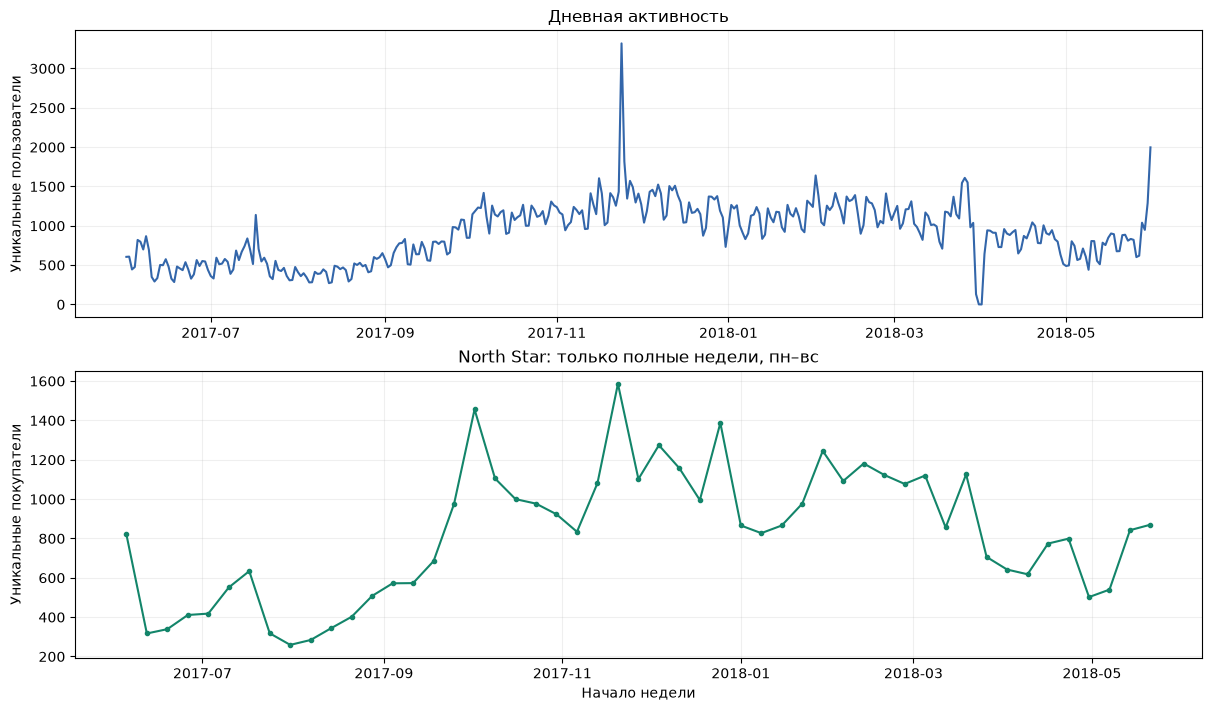

**Вывод:** средний DAU = **906**, средний WAU полной недели = **5,805**, средняя North Star = **822 покупателей в неделю**. Колебания требуют проверки календаря мероприятий и сезонности; они не доказывают эффект рекламы.

In [10]:
figure, axes = plt.subplots(2, 1, figsize=(12, 7), layout="constrained")

axes[0].plot(daily_active_users.index, daily_active_users.values, color="#3366aa")
axes[0].set_title("Дневная активность")
axes[0].set_ylabel("Уникальные пользователи")

week_start_dates = full_week_metrics.index.to_timestamp()
axes[1].plot(
    week_start_dates,
    full_week_metrics["покупатели"],
    color="#13856a",
    marker=".",
)
axes[1].set_title("North Star: только полные недели, пн–вс")
axes[1].set_ylabel("Уникальные покупатели")
axes[1].set_xlabel("Начало недели")
plt.show()

activity_conclusion = (
    f"**Вывод:** средний DAU = **{average_dau:,.0f}**, "
    f"средний WAU полной недели = **{average_wau:,.0f}**, "
    f"средняя North Star = **{average_weekly_buyers:,.0f} покупателей в неделю**. "
    "Колебания требуют проверки календаря мероприятий и сезонности; "
    "они не доказывают эффект рекламы."
)
display(Markdown(activity_conclusion))

### 6.3. Какая доля новых посетителей покупает за неделю

Нас интересует переход от первого знакомства с сервисом к покупке.
Считаем долю новых посетителей, у которых первая покупка произошла
в течение 7 суток после первого визита. Семидневный горизонт — единое правило проекта,
которое даёт каждому пользователю одинаковое время на решение.

В знаменатель включаем только пользователей с полными 7 сутками наблюдения.
Пришедших позже исключаем из этого расчёта: отсутствие покупки у них пока может означать,
что нужное время ещё не прошло. Покупка ровно через 7 суток уже находится за границей окна.

Помимо общей конверсии смотрим результат по каналу первого визита.
Различия помогут выбрать, где исследовать качество аудитории и путь к покупке,
но сами по себе не докажут, что причина именно в рекламном канале.

In [11]:
conversion_deadline = users["first_visit"] + CONVERSION_WINDOW
users["has_full_7_days"] = conversion_deadline <= analysis_end
users["converted_in_7_days"] = (
    (users["first_buy"] >= users["first_visit"])
    & (users["first_buy"] < conversion_deadline)
)

conversion_users = users.loc[users["has_full_7_days"]]
conversion_by_channel = conversion_users.groupby("first_source").agg(
    посетители=("uid", "size"),
    покупатели7=("converted_in_7_days", "sum"),
)
conversion_by_channel["C7"] = (
    conversion_by_channel["покупатели7"]
    / conversion_by_channel["посетители"]
)
conversion_7_days = conversion_users["converted_in_7_days"].mean()
excluded_conversion_users = len(users) - len(conversion_users)
display(conversion_by_channel)

conversion_conclusion = (
    f"**Вывод:** C7 = **{conversion_7_days:.2%}**, "
    f"знаменатель — **{len(conversion_users):,}** посетителей с полным окном. "
    f"Без полного окна исключено {excluded_conversion_users:,} посетителей. "
    "Различия каналов описательные: состав аудитории и сезонность "
    "могут влиять на результат."
)
display(Markdown(conversion_conclusion))

,посетители,покупатели7,C7
first_source,,,
1,9238,2429,0.263
2,16842,2454,0.146
3,64926,8091,0.125
4,70807,8060,0.114
5,48478,5660,0.117
6,2,0,0.000
7,31,1,0.032
9,6380,580,0.091
10,6664,1075,0.161


**Вывод:** C7 = **12.69%**, знаменатель — **223,368** посетителей с полным окном. Без полного окна исключено 4,801 посетителей. Различия каналов описательные: состав аудитории и сезонность могут влиять на результат.

### 6.4. Возвращаются ли пользователи в следующие месяцы

Конверсия описывает покупку, но не отвечает на вопрос о повторном использовании сервиса.
Для этого объединяем пользователей в когорты по месяцу первого визита
и смотрим, какая часть каждой когорты приходит в следующие календарные месяцы.
Например, для июньской когорты M1 — это июль, M2 — август.

Знаменатель сохраняется: это все пользователи исходной когорты.
M0 равен 100%, потому что каждый её участник по определению пришёл в этот месяц.
Ячейка с нулём означает, что месяц наблюдался, но возвратов не было.
Пустая ячейка (`NaN`) означает, что этот месяц ещё не наступил в пределах выгрузки.
Так не смешиваем отсутствие возвратов с отсутствием возможности их увидеть.

Общий M1 считаем как число вернувшихся пользователей, делённое на размер всех когорт
с полным следующим месяцем. Такое взвешивание учитывает разный размер когорт.
Для сервиса мероприятий результат нужно интерпретировать с учётом нерегулярной потребности:
человек может вернуться за новым билетом позже, чем через месяц.

In [12]:
cohort_activity = visits_in_period[["uid", "start"]].merge(
    users[["uid", "cohort"]],
    on="uid",
    validate="many_to_one",
)
cohort_activity["month"] = cohort_activity["start"].dt.to_period("M")
activity_month_number = cohort_activity["month"].astype("int64")
cohort_month_number = cohort_activity["cohort"].astype("int64")
cohort_activity["age"] = activity_month_number - cohort_month_number

cohort_sizes = users.groupby("cohort")["uid"].nunique()
active_users_by_cohort = cohort_activity.groupby(["cohort", "age"])["uid"].nunique()
cohort_counts = active_users_by_cohort.unstack(fill_value=0)
cohort_counts = cohort_counts.reindex(
    index=cohort_sizes.index,
    columns=range(12),
).astype(float)

# Сначала считаем наблюдаемые ячейки. Будущие месяцы маскируем отдельно.
last_observed_month = last_analysis_day.to_period("M")
for cohort in cohort_counts.index:
    observed_age = last_observed_month.ordinal - cohort.ordinal
    for age in cohort_counts.columns:
        if age > observed_age:
            cohort_counts.loc[cohort, age] = np.nan

retention = cohort_counts.div(cohort_sizes, axis="index")
assert (retention[0] == 1).all()
assert retention.stack().dropna().between(0, 1).all()

cohorts_with_m1 = retention[1].notna()
returning_users_m1 = cohort_counts.loc[cohorts_with_m1, 1].sum()
eligible_users_m1 = cohort_sizes.loc[cohorts_with_m1].sum()
retention_m1 = returning_users_m1 / eligible_users_m1
display(retention.round(4))

age,0,1,2,3,4,5,6,7,8,9,10,11
cohort,,,,,,,,,,,,
2017-06,1.000,0.079,0.054,0.061,0.069,0.071,0.061,0.058,0.052,0.051,0.041,0.045
2017-07,1.000,0.056,0.051,0.056,0.058,0.048,0.045,0.046,0.039,0.029,0.028,NaN
2017-08,1.000,0.077,0.063,0.063,0.050,0.044,0.036,0.040,0.028,0.026,NaN,NaN
2017-09,1.000,0.086,0.069,0.051,0.039,0.038,0.036,0.024,0.023,NaN,NaN,NaN
2017-10,1.000,0.079,0.052,0.039,0.034,0.032,0.021,0.020,NaN,NaN,NaN,NaN
2017-11,1.000,0.078,0.044,0.039,0.034,0.023,0.022,NaN,NaN,NaN,NaN,NaN
2017-12,1.000,0.056,0.038,0.031,0.020,0.019,NaN,NaN,NaN,NaN,NaN,NaN
2018-01,1.000,0.060,0.039,0.025,0.020,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-02,1.000,0.057,0.025,0.020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


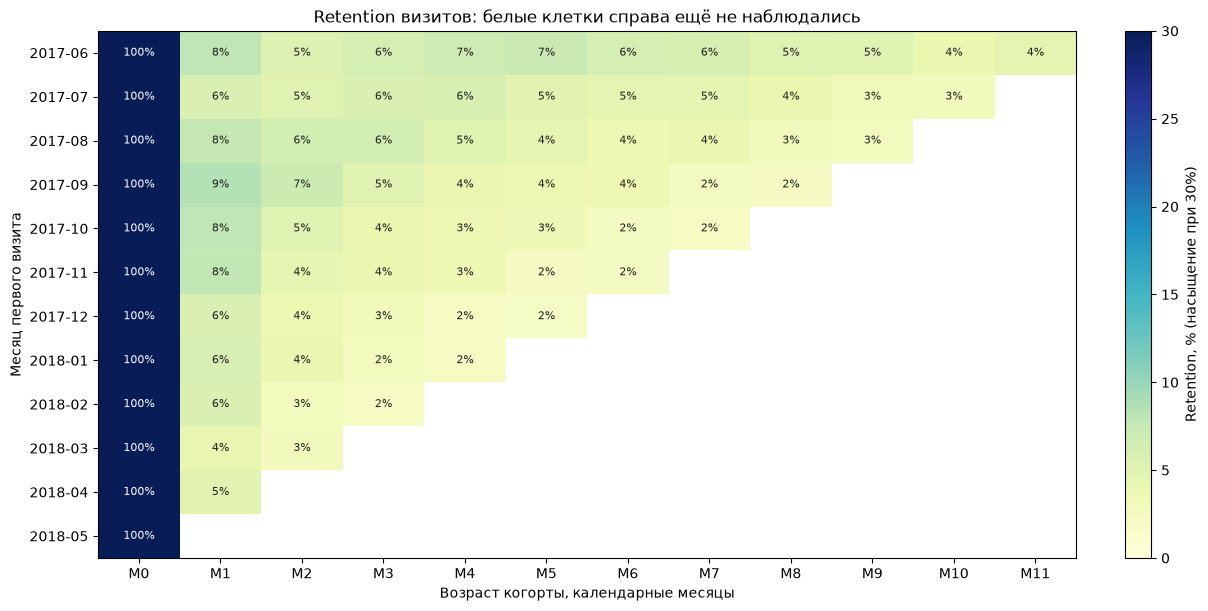

**Вывод:** взвешенный M1 = **6.49%** по 11 зрелым когортам. Низкий возврат — повод проверить регулярность потребности и качество привлечения. Для событийного сервиса отсутствие ежемесячного визита не всегда означает потерю ценности.

In [13]:
figure, axis = plt.subplots(figsize=(12, 6), layout="constrained")
heatmap = axis.imshow(
    retention.to_numpy() * 100,
    vmin=0,
    vmax=30,
    cmap="YlGnBu",
    aspect="auto",
)

for row in range(len(retention)):
    for column in range(len(retention.columns)):
        value = retention.iloc[row, column]
        if pd.isna(value):
            continue
        text_color = "white" if value > 0.18 else "#222222"
        axis.text(
            column, row, f"{value:.0%}",
            ha="center", va="center", fontsize=8, color=text_color,
        )

axis.set_xticks(range(12), labels=[f"M{age}" for age in range(12)])
axis.set_yticks(range(len(retention)), labels=retention.index.astype(str))
axis.set_xlabel("Возраст когорты, календарные месяцы")
axis.set_ylabel("Месяц первого визита")
axis.set_title("Retention визитов: белые клетки справа ещё не наблюдались")
axis.grid(False)
figure.colorbar(heatmap, ax=axis, label="Retention, % (насыщение при 30%)")
plt.show()

retention_conclusion = (
    f"**Вывод:** взвешенный M1 = **{retention_m1:.2%}** "
    f"по {cohorts_with_m1.sum()} зрелым когортам. "
    "Низкий возврат — повод проверить регулярность потребности и качество привлечения. "
    "Для событийного сервиса отсутствие ежемесячного визита "
    "не всегда означает потерю ценности."
)
display(Markdown(retention_conclusion))

### 6.5. Покрывают ли покупки расходы на привлечение

Теперь сопоставим выручку привлечённых покупателей с рекламными затратами.
Полную будущую выручку клиента мы не знаем, поэтому выбираем одинаковый горизонт —
**90 суток после первого визита**. Включаем только целиком наблюдаемые когорты,
чтобы у всех пользователей было одинаковое время на покупки.

Расчёт строится в три шага:

1. Для каждой когорты и канала первого визита находим покупателей за 90 суток
   и суммируем все их покупки в этом окне.
2. Сопоставляем с ними расходы того же канала за календарный месяц привлечения.
3. Делим выручку и расходы на одно и то же число покупателей.
   Получаем LTV90, CAC90 и их отношение. В агрегате используем суммы выручки и затрат,
   а не среднее отношений отдельных каналов.

Сопоставление расходов — главное допущение этого расчёта.
Мы относим месячный бюджет канала к пользователям, впервые замеченным в этом месяце.
В действительности часть бюджета могла быть потрачена на повторное привлечение старых клиентов,
а до покупки пользователь мог взаимодействовать с несколькими каналами.
Данные не позволяют разделить эти случаи, поэтому CAC90 рассматриваем как приближённую оценку.

Отношение ниже 1 означает, что записанная 90-дневная выручка меньше сопоставленных рекламных расходов.
Отношение выше 1 ещё не подтверждает прибыльность: нет себестоимости, возвратов и маржи.
Для каналов без расходов отношение не вычисляем, поскольку неизвестная стоимость не равна нулю.

После основного расчёта повторно оцениваем отношение без покупок выше общего 99-го процентиля выручки.
Это покажет зависимость результата от крупных покупок, не заменяя исходный расчёт.

In [14]:
# Включаем месяц целиком: даже привлечённые в самом конце месяца
# должны иметь 90 полных суток наблюдения.
next_month_start = (users["cohort"] + 1).dt.to_timestamp()
cohort_observation_end = next_month_start + REVENUE_WINDOW
users["has_full_90_day_cohort"] = cohort_observation_end <= analysis_end
mature_cohort_months = sorted(
    users.loc[users["has_full_90_day_cohort"], "cohort"].unique()
)

orders_with_cohorts = orders_in_period.merge(
    users[["uid", "first_visit", "cohort", "first_source"]],
    on="uid",
    validate="many_to_one",
)
revenue_deadline = orders_with_cohorts["first_visit"] + REVENUE_WINDOW
within_90_days = (
    (orders_with_cohorts["buy"] >= orders_with_cohorts["first_visit"])
    & (orders_with_cohorts["buy"] < revenue_deadline)
)
in_mature_cohort = orders_with_cohorts["cohort"].isin(mature_cohort_months)
orders_first_90_days = orders_with_cohorts.loc[
    within_90_days & in_mature_cohort
].copy()

mature_users = users.loc[users["cohort"].isin(mature_cohort_months)]
cohort_keys = ["cohort", "first_source"]
cohort_visitors = mature_users.groupby(cohort_keys)["uid"].nunique()
cohort_visitors = cohort_visitors.rename("visitors")
cohort_revenue = orders_first_90_days.groupby(cohort_keys).agg(
    buyers90=("uid", "nunique"),
    revenue90=("revenue", "sum"),
)

monthly_costs = costs_in_period.copy()
monthly_costs["cohort"] = monthly_costs["date"].dt.to_period("M")
monthly_costs = monthly_costs.loc[
    monthly_costs["cohort"].isin(mature_cohort_months)
]
cohort_costs = monthly_costs.groupby(["cohort", "source"])["costs"].sum()
cohort_costs.index.names = cohort_keys

In [15]:
cohort_economics = cohort_visitors.to_frame()
cohort_economics = cohort_economics.join(cohort_revenue, how="outer")
cohort_economics = cohort_economics.join(cohort_costs, how="outer")

# Нет покупок — нулевая наблюдаемая выручка.
# Нет расходов — неизвестная стоимость, поэтому costs не заполняем нулём.
for column in ["visitors", "buyers90", "revenue90"]:
    cohort_economics[column] = cohort_economics[column].fillna(0)

buyer_denominator = cohort_economics["buyers90"].replace(0, np.nan)
cost_denominator = cohort_economics["costs"].replace(0, np.nan)
cohort_economics["LTV90"] = cohort_economics["revenue90"] / buyer_denominator
cohort_economics["CAC90"] = cohort_economics["costs"] / buyer_denominator
cohort_economics["LTV90_CAC90"] = (
    cohort_economics["revenue90"] / cost_denominator
)
display(cohort_economics.round(3))

cohort_sources = cohort_economics.index.get_level_values("first_source")
has_recorded_costs = cohort_sources.isin(paid_sources)
paid_cohort_economics = cohort_economics.loc[has_recorded_costs].copy()
unpriced_cohort_economics = cohort_economics.loc[~has_recorded_costs].copy()
assert paid_cohort_economics["costs"].notna().all()

sum_columns = ["visitors", "buyers90", "revenue90", "costs"]
channel_economics = paid_cohort_economics.groupby("first_source")[sum_columns].sum()
channel_buyers = channel_economics["buyers90"].replace(0, np.nan)
channel_costs = channel_economics["costs"].replace(0, np.nan)
channel_economics["LTV90"] = channel_economics["revenue90"] / channel_buyers
channel_economics["CAC90"] = channel_economics["costs"] / channel_buyers
channel_economics["LTV90_CAC90"] = channel_economics["revenue90"] / channel_costs
display(channel_economics.round(3))

visitors  buyers90  revenue90     costs  LTV90  CAC90  \
cohort  first_source                                                          
2017-06 1                  631   210.000  2,930.000 1,125.610 13.952  5.360   
        2                 1262   278.000  1,556.410 2,427.380  5.599  8.732   
        3                 4080   710.000  3,897.630 7,731.650  5.490 10.890   
        4                 3447   486.000  2,519.470 3,514.800  5.184  7.232   
        5                 2728   432.000  2,692.690 2,616.120  6.233  6.056   
...                        ...       ...        ...       ...    ...    ...   
2018-02 4                 7152   931.000  4,141.040 5,711.960  4.448  6.135   
        5                 4556   600.000  2,722.610 5,071.310  4.538  8.452   
        7                    2     0.000      0.000       NaN    NaN    NaN   
        9                  454    49.000    233.340   551.500  4.762 11.255   
        10                 842   113.000    261.920   480.880  2.318  4.256   

                      LTV90_CAC90  
cohort  first_source               
2017-06 1                   2.603  
        2                   0.641  
        3                   0.504  
        4                   0.717  
        5                   1.029  
...                           ...  
2018-02 4                   0.725  
        5                   0.537  
        7                     NaN  
        9                   0.423  
        10                  0.545  

[74 rows x 7 columns]

,visitors,buyers90,revenue90,costs,LTV90,CAC90,LTV90_CAC90
first_source,,,,,,,
1,7148,"2,161.000","16,223.360","16,145.080",7.507,7.471,1.005
2,13334,"2,415.000","26,483.150","33,179.760",10.966,13.739,0.798
3,52469,"7,760.000","38,338.270","109,532.550",4.940,14.115,0.350
4,54560,"7,495.000","35,419.360","46,489.030",4.726,6.203,0.762
5,39063,"5,360.000","30,844.480","40,056.770",5.755,7.473,0.770
9,5068,730.000,"3,323.350","4,301.540",4.553,5.893,0.773
10,4926,894.000,"2,854.480","4,497.970",3.193,5.031,0.635


In [16]:
total_buyers_90 = paid_cohort_economics["buyers90"].sum()
total_revenue_90 = paid_cohort_economics["revenue90"].sum()
total_acquisition_costs = paid_cohort_economics["costs"].sum()

ltv_90 = total_revenue_90 / total_buyers_90
cac_90 = total_acquisition_costs / total_buyers_90
ltv_cac_ratio_90 = ltv_90 / cac_90

# Сценарий чувствительности сохраняет исходный бюджет и исключает
# только покупки, превышающие общий p99 выручки одного заказа.
is_paid_order = orders_first_90_days["first_source"].isin(paid_sources)
below_revenue_threshold = orders_first_90_days["revenue"] <= revenue_p99
revenue_without_tail = orders_first_90_days.loc[
    is_paid_order & below_revenue_threshold,
    "revenue",
].sum()
ratio_without_large_orders = revenue_without_tail / total_acquisition_costs

economics_summary = pd.Series({
    "зрелые месяцы": ", ".join(map(str, mature_cohort_months)),
    "покупатели90 платных каналов": int(total_buyers_90),
    "выручка90 платных каналов": total_revenue_90,
    "расходы их месяцев": total_acquisition_costs,
    "LTV90": ltv_90,
    "CAC90": cac_90,
    "LTV90/CAC90": ltv_cac_ratio_90,
    "отношение без покупок выше общего p99": ratio_without_large_orders,
    "посетители каналов без расходов": int(unpriced_cohort_economics["visitors"].sum()),
    "выручка90 каналов без расходов": unpriced_cohort_economics["revenue90"].sum(),
})
display(economics_summary.to_frame("значение"))

,значение
зрелые месяцы,"2017-06, 2017-07, 2017-08, 2017-09, 2017-10, 2017-11, 2017-12, 2018-01, 2018-02"
покупатели90 платных каналов,26815
выручка90 платных каналов,"153,486.450"
расходы их месяцев,"254,202.700"
LTV90,5.724
CAC90,9.480
LTV90/CAC90,0.604
отношение без покупок выше общего p99,0.520
посетители каналов без расходов,30
выручка90 каналов без расходов,1.220


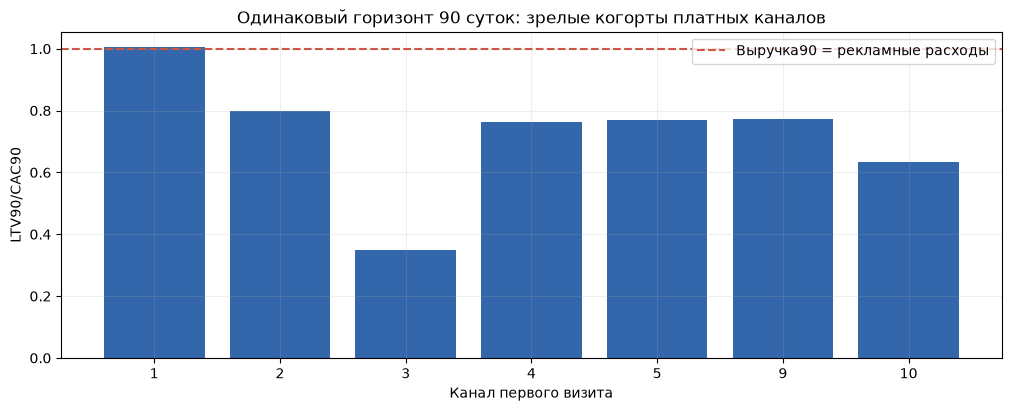

**Вывод:** LTV90 = **5.72**, CAC90 = **9.48** ден. ед., отношение = **0.604**. В совокупности наблюдаемая 90-дневная выручка ниже рекламных расходов. Канал 3 с наибольшим объёмом затрат требует первоочередной проверки; канал 1 близок к покрытию расходов по выручке, что ещё не означает положительную маржу. Без покупок выше общего p99 отношение = **0.520**. Это проверка зависимости от крупных покупок. Значение выше 1 означает только покрытие рекламных затрат выручкой за 90 дней, а не прибыльность. Каналы без расходов не сравниваются по CAC.

In [17]:
figure, axis = plt.subplots(figsize=(10, 4), layout="constrained")
axis.bar(
    channel_economics.index.astype(str),
    channel_economics["LTV90_CAC90"],
    color="#3366aa",
)
axis.axhline(
    1,
    color="#cc5544",
    linestyle="--",
    label="Выручка90 = рекламные расходы",
)
axis.set_xlabel("Канал первого визита")
axis.set_ylabel("LTV90/CAC90")
axis.set_title("Одинаковый горизонт 90 суток: зрелые когорты платных каналов")
axis.legend()
plt.show()

economics_conclusion = (
    f"**Вывод:** LTV90 = **{ltv_90:.2f}**, CAC90 = **{cac_90:.2f}** ден. ед., "
    f"отношение = **{ltv_cac_ratio_90:.3f}**. "
    "В совокупности наблюдаемая 90-дневная выручка ниже рекламных расходов. "
    "Канал 3 с наибольшим объёмом затрат требует первоочередной проверки; "
    "канал 1 близок к покрытию расходов по выручке, "
    "что ещё не означает положительную маржу. "
    f"Без покупок выше общего p99 отношение = **{ratio_without_large_orders:.3f}**. "
    "Это проверка зависимости от крупных покупок. Значение выше 1 означает "
    "только покрытие рекламных затрат выручкой за 90 дней, а не прибыльность. "
    "Каналы без расходов не сравниваются по CAC."
)
display(Markdown(economics_conclusion))

### 6.6. Длительное отсутствие и сводка показателей

Дополнительно определим пользователей, у которых к концу наблюдения прошло
не менее 30 суток с последнего визита. Это позволяет оценить масштаб неактивной аудитории на срезе.
Такой показатель отличается от retention: retention сравнивает возврат когорт
на одинаковом этапе их жизни, а здесь мы смотрим на последнее посещение каждого человека.
Последующие возвращения за пределами выгрузки нам неизвестны.

В сводную таблицу выносим основные показатели, с которыми будем сравнивать будущие результаты.
Для North Star берём среднее последних восьми полных недель — заранее определённый
недавний период. Конверсия, M1 и экономика сохраняют собственные окна,
поэтому их базовые значения относятся к разным допустимым группам наблюдений.

In [18]:
last_visit_by_user = visits_in_period.groupby("uid")["start"].max()
churn_cutoff = analysis_end - CHURN_WINDOW
churn_signal = last_visit_by_user <= churn_cutoff

print(
    f"Без визитов не менее 30 суток на срезе: "
    f"{churn_signal.sum():,} / {len(last_visit_by_user):,} "
    f"({churn_signal.mean():.2%})"
)

baseline_weekly_buyers = full_week_metrics["покупатели"].tail(8).mean()
metric_summary = pd.DataFrame([
    {
        "метрика": "North Star: среднее последних 8 полных недель",
        "базовое значение": baseline_weekly_buyers,
        "единица": "покупателей/неделю",
    },
    {
        "метрика": "C7, все зрелые пользователи",
        "базовое значение": conversion_7_days,
        "единица": "доля",
    },
    {
        "метрика": "M1, взвешенный по зрелым когортам",
        "базовое значение": retention_m1,
        "единица": "доля",
    },
    {
        "метрика": "LTV90/CAC90, зрелые платные когорты",
        "базовое значение": ltv_cac_ratio_90,
        "единица": "отношение",
    },
])
display(metric_summary)

Без визитов не менее 30 суток на срезе: 207,867 / 228,169 (91.10%)


,метрика,базовое значение,единица
0,North Star: среднее последних 8 полных недель,698.375,покупателей/неделю
1,"C7, все зрелые пользователи",0.127,доля
2,"M1, взвешенный по зрелым когортам",0.065,доля
3,"LTV90/CAC90, зрелые платные когорты",0.604,отношение


## 7. Как использовать данные ответственно

В файлах нет имён и контактов, но есть устойчивые идентификаторы пользователей и время их действий.
Поэтому мы не можем считать данные полностью анонимными.
Кроме того, открытая страница Kaggle не объясняет, как собиралась история
и на каких условиях её разрешено использовать. Эти вопросы учитываем отдельно от технического качества таблиц.

| Вопрос | Что важно в нашем случае | Как поступаем |
|---|---|---|
| Цель | История действий нужна для учебного анализа продукта | Работаем с активностью, конверсией и экономикой на уровне групп; не составляем профили отдельных людей |
| Согласие и основание сбора | В источнике нет подтверждения согласия пользователей и условий первоначального сбора | Фиксируем неизвестный статус; до расширения использования и публикации сырых данных нужно уточнить условия у автора |
| Специальные категории | Явных полей о здоровье, религии и других чувствительных признаках нет; связывание действий с внешними данными может раскрыть лишнюю информацию | Не пытаемся установить личности и не соединяем выгрузку с внешними персональными источниками |
| Передача третьим лицам | Публикация CSV в Git передаст пользовательские ID и время действий третьим лицам | Фиксируем риск; не добавляем внешние персональные сведения. Доступность репозитория и допустимость передачи требуют оценки до публикации |
| Хранение | Для проекта не требуется бессрочно хранить сырые логи | Предлагаем ограничить доступ участниками и удалить локальные CSV и архив в течение 30 дней после защиты, если нет другого основания хранения |
| Удаление | Мы контролируем локальные копии, но не исходную публикацию Kaggle | При завершении работы удаляем свои копии; для будущего продукта потребуется процедура удаления истории по проверенному запросу пользователя |
| Лицензия | В Kaggle API указано `Unknown` | Сохраняем автора, ссылку и версию; включение CSV в проект не подтверждает разрешение на распространение, условия нужно уточнить у автора |
| Происхождение | Подтверждена публикация Ella Nihill на Kaggle, но первичный сбор не описан | Не утверждаем, что согласие и анонимизация проверены; запрашиваем описание происхождения перед дальнейшим использованием |
| Публикация результатов | Очень маленькие группы могут повышать риск связывания с внешними сведениями | В текущем ноутбуке не выводим отдельные ID; для будущих публичных срезов предлагаем скрывать группы меньше 10 человек |

Результаты расчётов выводятся без отдельных пользовательских ID, но исходные CSV содержат эти ID.
Поскольку файлы подготовлены для Git, риск передачи исходной истории при публикации остаётся открытым.
Срок удаления и ограничение малых групп — предлагаемые правила проекта, которые команда должна принять
перед соответствующей публикацией. Вопросы лицензии и основания сбора остаются открытыми:
их нельзя решить одним техническим обезличиванием.

## 8. Как поймём, что проект дал результат

Рассчитанные значения задают начальную точку, но сами по себе не говорят об улучшении продукта.
Для следующего этапа выбираем три цели: увеличить число недельных покупателей на 10%,
повысить C7 на 2 процентных пункта и довести LTV90/CAC90 как минимум до 1
с одновременным ориентиром на рост отношения не менее чем на 10% от базы.
Эти пороги — предложенные цели проекта, а не прогноз, полученный из данных.

Первые две цели соответствуют росту покупающей аудитории и улучшению перехода к покупке.
Третья ограничивает рост затратами: по текущей оценке 90-дневной выручки недостаточно
для покрытия сопоставленного рекламного бюджета. Порог 1 — минимальная проверка покрытия рекламы,
а требование прибыльности можно будет задать только после уточнения маржи.
Retention M1 оставляем диагностикой: его изменение поможет объяснять результат,
но отдельную целевую величину без проверки частоты потребности пока не назначаем.

Ниже переводим цели в численные значения и указываем способ проверки.
Сравнение потребует новых наблюдений с теми же определениями и полными окнами;
по возможности используем эксперимент или контроль, чтобы учесть сезонность и состав аудитории.
Для проверки экономики придётся дождаться полного 90-дневного окна новых когорт.

К финалу можно проверить качество аналитической работы: повторяемость расчётов,
согласованность определений и обоснованность выводов. Подтвердить рост самого продукта
на неизменной исторической выгрузке нельзя. Если новых данных не будет,
продуктовые цели останутся со статусом **«не проверено»**.

In [19]:
target_weekly_buyers = baseline_weekly_buyers * 1.10
target_conversion = conversion_7_days + 0.02
target_ltv_cac_ratio = max(1.0, ltv_cac_ratio_90 * 1.10)

success_targets = pd.DataFrame([
    {
        "метрика": "Недельные покупатели",
        "база": f"{baseline_weekly_buyers:.1f}",
        "цель к финалу": f"≥ {target_weekly_buyers:.1f} (+10%)",
        "проверка": (
            "Новые 8 полных недель после изменения; одинаковая длительность, "
            "проверка сезонности и A/B либо сопоставимого контроля"
        ),
    },
    {
        "метрика": "C7",
        "база": f"{conversion_7_days:.2%}",
        "цель к финалу": f"≥ {target_conversion:.2%} (+2 п.п.)",
        "проверка": (
            "Новая когорта с полными 7 сутками; та же first-touch схема; "
            "разница конверсий и 95% ДИ, предпочтительно A/B"
        ),
    },
    {
        "метрика": "LTV90/CAC90",
        "база": f"{ltv_cac_ratio_90:.3f}",
        "цель к финалу": f"≥ {target_ltv_cac_ratio:.3f}",
        "проверка": (
            "Новые полностью зрелые 90-дневные когорты платных каналов; "
            "те же окна и стоимость; отдельно подтвердить маржу и единицы валюты"
        ),
    },
])
display(success_targets)

display(Markdown(
    "**Критерий аналитической готовности:** Run All без ошибок; совпадение SHA-256; "
    "полные окна; проверяемые знаменатели; таблицы и выводы согласованы. "
    "**Критерий продуктового результата:** проверка целей на новых данных; "
    "при отсутствии новых наблюдений статус «не проверено», а не «достигнуто»."
))

,метрика,база,цель к финалу,проверка
0,Недельные покупатели,698.4,≥ 768.2 (+10%),"Новые 8 полных недель после изменения; одинаковая длительность, проверка сезонности и A/B либо сопоставимого контроля"
1,C7,12.69%,≥ 14.69% (+2 п.п.),"Новая когорта с полными 7 сутками; та же first-touch схема; разница конверсий и 95% ДИ, предпочтительно A/B"
2,LTV90/CAC90,0.604,≥ 1.000,Новые полностью зрелые 90-дневные когорты платных каналов; те же окна и стоимость; отдельно подтвердить маржу и единицы валюты


**Критерий аналитической готовности:** Run All без ошибок; совпадение SHA-256; полные окна; проверяемые знаменатели; таблицы и выводы согласованы. **Критерий продуктового результата:** проверка целей на новых данных; при отсутствии новых наблюдений статус «не проверено», а не «достигнуто».

## 9. Как воспроизвести работу и что осталось перед сдачей

Все содержательные разделы и расчёты находятся в этом ноутбуке.
В [репозитории Dvizhuha_PA](https://github.com/Andre1ka11/Dvizhuha_PA)
также предусмотрены файлы для повторного запуска:

- `README.md` объясняет задачу, источник данных, команды запуска и основные результаты.
- `requirements.txt` фиксирует версии библиотек.
- `data/raw/` содержит три исходных CSV, которые ноутбук читает напрямую.
- `data/manifest.json` фиксирует версию, размеры и SHA-256; проверка файлов выполняется в ноутбуке.
- `.gitignore` исключает окружения, временные файлы и кэши.

Для запуска нужно открыть корень репозитория, создать окружение и установить зависимости
по инструкции в README. После этого можно выполнить ноутбук в VS Code/Jupyter
через **Restart Kernel → Run All**. Отдельные Python-скрипты для запуска не нужны.
Данные читаются по относительным путям, поэтому расположение проекта на компьютере можно менять.

### Участники и распределение работы

В команде четыре человека: Станислав, Андрей, Даниил и Елена.
Индивидуальный вклад пока не уточнён. Ниже приведён вариант распределения задач;
перед сдачей его нужно заменить фактическим вкладом участников.

| Участник | Предлагаемая часть работы |
|---|---|
| Станислав | Описание продукта, определения и выбор метрик |
| Андрей | Репозиторий, загрузка данных и воспроизводимость |
| Даниил | Проверка данных, когортный анализ и экономика привлечения |
| Елена | План трекинга, этический анализ и критерии успеха |

### Где найти требования PA-S1

| Требование | Раздел |
|---|---|
| Продукт, аудитория, проблема, ценность и бизнес-модель | 1 |
| Источник, версия, лицензия, объём, период и проверка качества | 2 |
| Единые определения пользователей, конверсии, удержания, когорты и оттока | 3 |
| North Star, две диагностические метрики и риск-метрика | 4 |
| Пять событий с триггерами, параметрами, метриками и полями источника | 5 |
| LTV/CAC и дополнительные расчёты: активность, C7, retention; таблицы, графики и выводы | 6 |
| Полный этический чек-лист | 7 |
| Численные цели и способы проверки | 8 |
| Запуск, файлы репозитория и сведения о команде | 9 и README |

Перед сдачей остаётся уточнить фактический вклад, согласовать с преподавателем
ограниченную оценку LTV90 по выручке и проверить условия использования датасета.
Текущие изменения нужно отправить в репозиторий и проверить доступность ссылки для проверяющего.

In [20]:
# Проверяем, что определения и знаменатели согласованы между расчётами.
assert users["uid"].is_unique
assert len(users) == visits_in_period["uid"].nunique()
assert cohort_sizes.sum() == len(users)
assert conversion_users["converted_in_7_days"].sum() <= len(conversion_users)

order_window_end = orders_first_90_days["first_visit"] + REVENUE_WINDOW
assert (orders_first_90_days["buy"] < order_window_end).all()
assert (
    orders_first_90_days["buy"] >= orders_first_90_days["first_visit"]
).all()

assert np.isclose(ltv_cac_ratio_90, total_revenue_90 / total_acquisition_costs)
assert np.isclose(ltv_90 / cac_90, ltv_cac_ratio_90)
actual_cohorts = paid_cohort_economics.index.get_level_values("cohort")
assert set(actual_cohorts) == set(mature_cohort_months)

print("Все проверки согласованности пройдены. Расчёты выполнены на Kaggle v1.")

Все проверки согласованности пройдены. Расчёты выполнены на Kaggle v1.
